# Fundus_CIMT_2903 → Artery/Vein masks (OCULARNet) — Kaggle, A to Z
Dataset: `Fundus_CIMT_2903 Dataset` (2903 patients × L/R = **5806** PNG).
Setup: **GPU T4**, **Internet ON**, dataset **Add Input** → **Run All**. Session kete gele abar Run All (resume hoy).

**Output (`/kaggle/working/av_masks.zip`)**
- `class_png/` : 0=bg, 1=artery, 2=vein, 3=crossing (original size)
- `color_png/` : artery RED, vein BLUE, crossing GREEN, **background PURE BLACK**
- `gray_png/` : viewer-e dekha jay (bg=0, artery=85, vein=170, crossing=255)
- `preview_overlay/` : fundus er upor mask | `preview_mask_black/` : shudhu mask, black bg
- `mapping.csv`, `README.txt`

In [1]:
# ===== CELL 1: CONFIG =====
CFG = dict(
    IMG_DIR   = None,       # None = auto-detect. Manual: "/kaggle/input/<slug>/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset"
    EXPECTED  = 5806,
    OUT_DIR   = "/kaggle/working/av_masks",
    ZIP_PATH  = "/kaggle/working/av_masks.zip",
    IM_SIZE   = 1024,       # OCULARNet 1024-e train; change korba na
    CROP_FOV  = True,       # black border crop -> square pad -> model; mask original size-e fire ashe
    BATCH     = 2,          # OOM hole 1
    TTA       = 2,          # 4 = best/slow | 2 = balanced | 1 = fastest
    FP16      = True,
    NUM_WORKERS = 2,
    N_PREVIEW = 12,
    SAVE_GRAY = True,       # gray_png folder
)

In [2]:
# ===== CELL 2: SETUP =====
import os, sys, glob, csv, subprocess, urllib.request, shutil, time
from pathlib import Path

os.chdir("/kaggle/working")
if not os.path.exists("OCULAR"):
    subprocess.run("git clone -q https://github.com/GonzaloPlaaza/OCULAR.git", shell=True, check=True)
subprocess.run("pip -q install segmentation-models-pytorch timm", shell=True)
sys.path.insert(0, "/kaggle/working/OCULAR")

WPATH = "/kaggle/working/OCULAR/pretrained_weights/OCULARNet/OCULARNet.pth"
os.makedirs(os.path.dirname(WPATH), exist_ok=True)
if not os.path.exists(WPATH) or os.path.getsize(WPATH) < 1e6:
    urllib.request.urlretrieve("https://huggingface.co/Anon-User-Retina/OCULARNet/resolve/main/OCULARNet.pth", WPATH)
print("weights MB:", round(os.path.getsize(WPATH) / 1e6, 1))

import cv2, torch, numpy as np, torch.nn.functional as F
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
try:
    from utils.get_model import get_model
except Exception as e:
    print("Import fail ->", e, "\n--- repo requirements.txt ---")
    print(open("/kaggle/working/OCULAR/requirements.txt").read()); raise
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, torch.cuda.get_device_name(0) if dev == "cuda" else "(GPU OFF!)")

weights MB: 1260.1
device: cuda Tesla T4


In [3]:
# ===== CELL 3: LOAD MODEL =====
model = get_model("base_unet_repvgg_b3", num_classes=4, in_c=3)
ck = torch.load(WPATH, map_location="cpu", weights_only=False)
sd = ck["model_state_dict"] if isinstance(ck, dict) and "model_state_dict" in ck else ck
print(model.load_state_dict(sd))
model.to(dev).eval()

model.safetensors: reconstructing file:   0%|          |  0.00B /  493MB            

model.safetensors: downloading bytes:           |  0.00B            

<All keys matched successfully>


Unet(
  (encoder): TimmUniversalEncoder(
    (model): FeatureListNet(
      (stem): RepVggBlock(
        (conv_kxk): ConvNormAct(
          (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (bn): BatchNormAct2d(
            64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): Identity()
          )
        )
        (conv_1x1): ConvNormAct(
          (conv): Conv2d(3, 64, kernel_size=(1, 1), stride=(2, 2), bias=False)
          (bn): BatchNormAct2d(
            64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): Identity()
          )
        )
        (drop_path): Identity()
        (attn): Identity()
        (act): ReLU(inplace=True)
      )
      (stages_0): Sequential(
        (0): RepVggBlock(
          (conv_kxk): ConvNormAct(
            (conv): Conv2d(64, 192, kernel_size=(3, 3), stride=(2, 2), padding=(1, 

In [4]:
# ===== CELL 4: FIND IMAGES =====
EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
def find_images(root):
    return sorted(str(p) for p in Path(root).rglob("*") if p.suffix.lower() in EXT)

if CFG["IMG_DIR"] is None:
    best, best_n = None, 0
    for d, _, fs in os.walk("/kaggle/input"):
        n = sum(Path(f).suffix.lower() in EXT for f in fs)
        if n > best_n: best, best_n = d, n
    CFG["IMG_DIR"] = best
paths = find_images(CFG["IMG_DIR"])
print("IMG_DIR:", CFG["IMG_DIR"]); print("Images found:", len(paths), "| expected:", CFG["EXPECTED"])
assert paths, "Image paoa jay nai - IMG_DIR manually dao"
if len(paths) != CFG["EXPECTED"]: print("WARNING: count match kore nai - folder check koro")

stems, seen = [], set()
for p in paths:
    s = Path(p).stem
    if s in seen: s = f"{Path(p).parent.name}_{s}"
    seen.add(s); stems.append(s)

OUT = CFG["OUT_DIR"]
for d in ["class_png", "color_png", "gray_png", "preview_overlay", "preview_mask_black"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)
done_set = set(os.path.splitext(f)[0] for f in os.listdir(f"{OUT}/class_png"))
todo = [i for i, s in enumerate(stems) if s not in done_set]
print("Already done:", len(paths) - len(todo), "| Remaining:", len(todo))
im0 = cv2.imread(paths[0]); print("first image:", Path(paths[0]).name, im0.shape)

IMG_DIR: /kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset
Images found: 5806 | expected: 5806
Already done: 0 | Remaining: 5806
first image: 100464002_L.png (512, 512, 3)


In [5]:
# ===== CELL 5: INFERENCE =====
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
PAL  = {1: (255, 0, 0), 2: (0, 0, 255), 3: (0, 255, 0)}   # artery=Red, vein=Blue, crossing=Green (RGB)
GRAY = np.array([0, 85, 170, 255], np.uint8)

def colorize(cm):
    """background = PURE BLACK (zeros), baki class rongin"""
    o = np.zeros((*cm.shape, 3), np.uint8)
    for k, c in PAL.items(): o[cm == k] = c
    return o

def fov_bbox(im):
    H, W = im.shape[:2]
    g = cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (5, 5), 0)
    ys, xs = np.where(g > 12)
    if len(xs) == 0: return 0, 0, W, H
    x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
    if (x1 - x0) * (y1 - y0) > 0.97 * H * W or (x1 - x0) < 0.3 * W or (y1 - y0) < 0.3 * H:
        return 0, 0, W, H
    return int(x0), int(y0), int(x1), int(y1)

class DS(Dataset):
    def __len__(self): return len(todo)
    def __getitem__(self, k):
        i = todo[k]
        im = cv2.imread(paths[i], cv2.IMREAD_COLOR)
        if im is None: return None
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        H, W = im.shape[:2]
        x0, y0, x1, y1 = fov_bbox(im) if CFG["CROP_FOV"] else (0, 0, W, H)
        crop = im[y0:y1, x0:x1]
        h, w = crop.shape[:2]; side = max(h, w)
        py, px = (side - h) // 2, (side - w) // 2
        sq = np.zeros((side, side, 3), np.uint8); sq[py:py + h, px:px + w] = crop
        x = cv2.resize(sq, (CFG["IM_SIZE"],) * 2, interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255.
        x = (torch.from_numpy(x.transpose(2, 0, 1)) - MEAN) / STD
        return x, i, (H, W, x0, y0, h, w, side, py, px)

def collate(b): return [x for x in b if x is not None]

@torch.inference_mode()
def forward_tta(x):
    with torch.autocast("cuda", enabled=CFG["FP16"] and dev == "cuda"):
        lg = model(x).float(); n = 1
        if CFG["TTA"] >= 2: lg += model(x.flip(-1)).float().flip(-1); n += 1
        if CFG["TTA"] >= 4:
            lg += model(x.flip(-2)).float().flip(-2)
            lg += model(x.flip(-1, -2)).float().flip(-1, -2); n += 2
    return lg / n

dl = DataLoader(DS(), batch_size=CFG["BATCH"], num_workers=CFG["NUM_WORKERS"], collate_fn=collate)
n_prev = len(os.listdir(f"{OUT}/preview_overlay"))
failed, t0 = [], time.time()

for batch in tqdm(dl, desc="OCULARNet A/V"):
    if not batch: continue
    x = torch.stack([b[0] for b in batch]).to(dev)
    try:
        prob = torch.softmax(forward_tta(x), dim=1)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        prob = torch.cat([torch.softmax(forward_tta(x[j:j+1]), dim=1) for j in range(len(batch))], 0)
    for j, (_, i, (H, W, x0, y0, h, w, side, py, px)) in enumerate(batch):
        try:
            pj = F.interpolate(prob[j:j+1], size=(side, side), mode="bilinear", align_corners=False)
            cm_c = pj.argmax(1)[0].cpu().numpy().astype(np.uint8)[py:py + h, px:px + w]
            cm = np.zeros((H, W), np.uint8); cm[y0:y0 + h, x0:x0 + w] = cm_c
            s = stems[i]
            col_bgr = cv2.cvtColor(colorize(cm), cv2.COLOR_RGB2BGR)
            cv2.imwrite(f"{OUT}/color_png/{s}.png", col_bgr)                       # black bg
            if CFG["SAVE_GRAY"]: cv2.imwrite(f"{OUT}/gray_png/{s}.png", GRAY[np.clip(cm, 0, 3)])
            if n_prev < CFG["N_PREVIEW"]:
                im = cv2.imread(paths[i])
                cv2.imwrite(f"{OUT}/preview_overlay/{s}.jpg", cv2.addWeighted(im, 0.6, col_bgr, 0.4, 0))
                cv2.imwrite(f"{OUT}/preview_mask_black/{s}.png", col_bgr)
                n_prev += 1
            cv2.imwrite(f"{OUT}/class_png/{s}.png", cm)                             # sobar sheshe = "done"
        except Exception as e:
            failed.append((paths[i], str(e)))

print(f"Finished in {(time.time()-t0)/60:.1f} min | failed: {len(failed)}")
for f in failed[:10]: print("  FAIL:", f)

OCULARNet A/V:   0%|          | 0/2903 [00:00<?, ?it/s]

Finished in 25.6 min | failed: 0


In [6]:
# ===== CELL 6: MAPPING CSV + ZIP =====
rows = []
for p, s in zip(paths, stems):
    cp = f"{OUT}/class_png/{s}.png"
    if not os.path.exists(cp): continue
    cm = cv2.imread(cp, cv2.IMREAD_UNCHANGED)
    pid, _, eye = s.rpartition("_")
    rows.append([p, s, pid, eye, f"class_png/{s}.png", f"color_png/{s}.png", cm.shape[0], cm.shape[1],
                 int((cm == 1).sum()), int((cm == 2).sum()), int((cm == 3).sum())])
with open(f"{OUT}/mapping.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["image", "stem", "patient_id", "eye", "class_mask", "color_mask", "H", "W",
                 "artery_px", "vein_px", "cross_px"])
    wr.writerows(rows)
print(f"masks: {len(rows)} / {len(paths)}")

with open(f"{OUT}/README.txt", "w") as f:
    f.write("Pseudo A/V masks for Fundus_CIMT_2903 generated by OCULARNet (base_unet_repvgg_b3, github.com/GonzaloPlaaza/OCULAR).\n"
            "class_png: 0=background, 1=artery, 2=vein, 3=crossing (original size, same filename).\n"
            "color_png: artery=red, vein=blue, crossing=green, background=black.\n"
            "gray_png: bg=0, artery=85, vein=170, crossing=255 (for visual inspection).\n")

shutil.make_archive(CFG["ZIP_PATH"][:-4], "zip", root_dir=os.path.dirname(OUT), base_dir=os.path.basename(OUT))
print("ZIP:", CFG["ZIP_PATH"], f"{os.path.getsize(CFG['ZIP_PATH'])/1e9:.2f} GB")

masks: 5806 / 5806
ZIP: /kaggle/working/av_masks.zip 0.25 GB


                   mean     min      max
artery_px  10396.299001  1989.0  14899.0
vein_px    13220.910265   764.0  19193.0
cross_px     509.982432    16.0   1145.0
Images with NO artery/vein predicted: 0
Eye counts: {'L': 2903, 'R': 2903}
Lowest-vessel images (manually check):
        stem  tot
643725002_L 3580
466627001_R 4923
570597001_R 6970
675600001_R 7623
459571001_L 8832


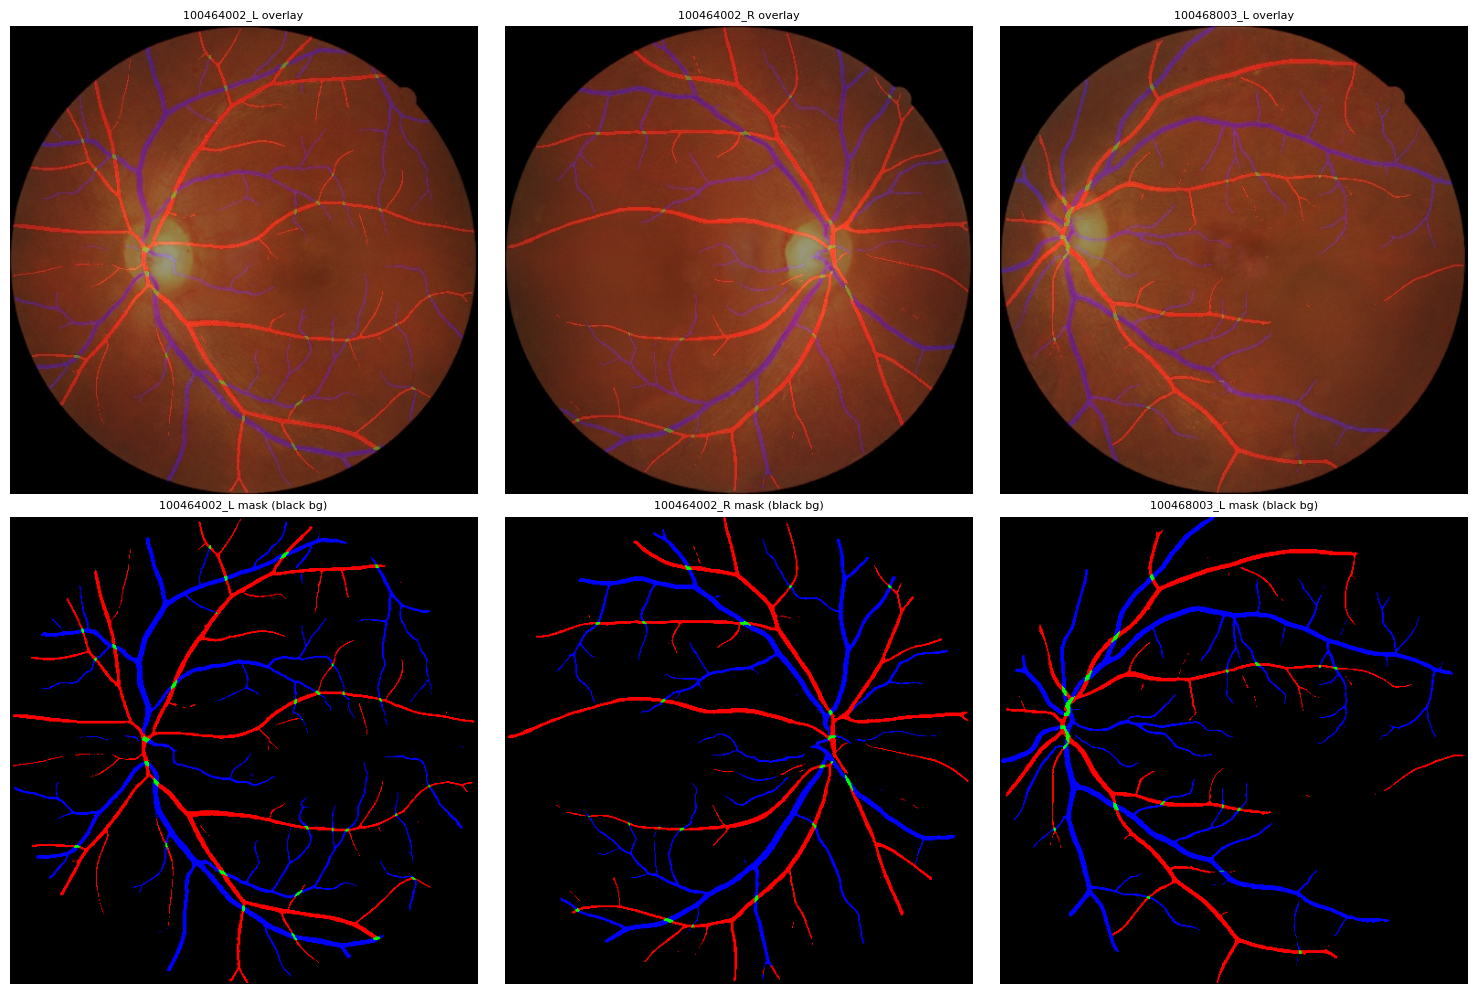

Artery=RED, Vein=BLUE, Crossing=GREEN, BG=BLACK | Download: /kaggle/working/av_masks.zip


In [7]:
# ===== CELL 7: VISUAL CHECK + STATS =====
import matplotlib.pyplot as plt, pandas as pd
df = pd.read_csv(f"{OUT}/mapping.csv")
print(df[["artery_px", "vein_px", "cross_px"]].describe().T[["mean", "min", "max"]])
print("Images with NO artery/vein predicted:", int(((df.artery_px + df.vein_px) == 0).sum()))
print("Eye counts:", df.eye.value_counts().to_dict())
low = df.assign(tot=df.artery_px + df.vein_px).nsmallest(5, "tot")[["stem", "tot"]]
print("Lowest-vessel images (manually check):\n", low.to_string(index=False))

ov = sorted(glob.glob(f"{OUT}/preview_overlay/*.jpg"))[:3]
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for k, p in enumerate(ov):
    s = Path(p).stem
    ax[0, k].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); ax[0, k].set_title(s + " overlay", fontsize=8)
    ax[1, k].imshow(cv2.cvtColor(cv2.imread(f"{OUT}/preview_mask_black/{s}.png"), cv2.COLOR_BGR2RGB))
    ax[1, k].set_title(s + " mask (black bg)", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
print("Artery=RED, Vein=BLUE, Crossing=GREEN, BG=BLACK | Download:", CFG["ZIP_PATH"])